# 1. Libraries' Import

The following libraries are used for data manipulation, statistical analysis,
data visualisation, machine learning and application development

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import missingno as msno

import sklearn
import scipy
import statsmodels.api as sm

import streamlit as st

print("all packages are imported!")

all packages are imported!


# 2. Data Loading and Initial Inspection

Data is loaded with pandas, and analysed for structure, shape and columns' statistics

In [4]:
df = pd.read_csv("../data/animal-shelter-intakes-and-outcomes.csv")
print("Data loaded successfully!")

Data loaded successfully!


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (58273, 29)


In [6]:
df.columns.tolist()

['Kennel ID',
 'Animal ID',
 'Animal Name',
 'Animal Type',
 'Primary Color',
 'Secondary Color',
 'Sex',
 'DOB',
 'Intake Date',
 'Intake Condition',
 'Intake Type',
 'Intake Subtype',
 'Reason for Intake',
 'Outcome Date',
 'Crossing',
 'Jurisdiction',
 'Outcome Type',
 'Outcome Subtype',
 'latitude',
 'longitude',
 'intake_is_dead',
 'geopoint',
 'intake_duration',
 'is_current_month',
 'outcome_is_dead',
 'outcome_is_current',
 'outcome_is_other',
 'outcome_is_alive',
 'was_outcome_alive']

In [7]:
df.head(5)

,Kennel ID,Animal ID,Animal Name,Animal Type,Primary Color,Secondary Color,Sex,DOB,Intake Date,Intake Condition,...,longitude,intake_is_dead,geopoint,intake_duration,is_current_month,outcome_is_dead,outcome_is_current,outcome_is_other,outcome_is_alive,was_outcome_alive
0,315049,A642578,*CILANTRO,CAT,BLACK,WHITE,Spayed,2017-02-06,2020-05-11,NORMAL,...,-118.198047,Alive on Intake,"33.7729101, -118.1980473",8.0,False,False,False,False,True,1
1,285027,A590559,*ALEXA,DOG,BROWN,WHITE,Female,2015-05-20,2017-05-20,NORMAL,...,-118.198047,Alive on Intake,"33.7729101, -118.1980473",25.0,False,False,False,False,True,1
2,295257,A608048,NaN,CAT,TORTIE,BLACK,Female,2018-03-23,2018-05-23,NORMAL,...,-118.198046,Alive on Intake,"33.77412870000001, -118.1980464",4.0,False,False,False,False,True,1
3,295243,A608031,CHARLIE,DOG,WHITE,TAN,Neutered,2016-05-23,2018-05-23,NORMAL,...,-118.198177,Alive on Intake,"33.7763762, -118.1981775",1.0,False,False,False,False,True,1
4,336591,A680414,*LEO,CAT,BRN TABBY,NaN,Male,2022-07-10,2022-07-20,UNDER AGE/WEIGHT,...,-118.198327,Alive on Intake,"33.7823404, -118.1983267",21.0,False,False,False,False,True,1


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58273 entries, 0 to 58272
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Kennel ID           58273 non-null  int64  
 1   Animal ID           58273 non-null  str    
 2   Animal Name         34722 non-null  str    
 3   Animal Type         58273 non-null  str    
 4   Primary Color       58273 non-null  str    
 5   Secondary Color     27267 non-null  str    
 6   Sex                 58273 non-null  str    
 7   DOB                 50690 non-null  str    
 8   Intake Date         58273 non-null  str    
 9   Intake Condition    58273 non-null  str    
 10  Intake Type         58273 non-null  str    
 11  Intake Subtype      57428 non-null  str    
 12  Reason for Intake   3648 non-null   str    
 13  Outcome Date        57993 non-null  str    
 14  Crossing            58106 non-null  str    
 15  Jurisdiction        58272 non-null  str    
 16  Outcome Type   

In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Kennel ID,58273.0,NaN,NaN,NaN,335300.322911,38322.75181,238448.0,302595.0,330947.0,357977.0,420108.0
Animal ID,58273,56128,A637086,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Animal Name,34722,14815,*,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Animal Type,58273,10,CAT,27638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Primary Color,58273,86,BLACK,14926,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Secondary Color,27267,54,WHITE,16121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,58273,5,Unknown,12761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DOB,50690,7039,2018-04-10,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Intake Date,58273,3617,2023-05-03,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Intake Condition,58273,17,NORMAL,25341,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 3. Data Quality Assessment

This section assesses the dataset for completeness and duplicates

## 3.1 Missing values

In [10]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[
    missing_values['Missing Count'] > 0
].sort_values(by='Missing Percentage', ascending=False)

missing_values.round(2)

,Missing Count,Missing Percentage
Reason for Intake,54625,93.74
Secondary Color,31006,53.21
Animal Name,23551,40.41
DOB,7583,13.01
Outcome Subtype,5844,10.03
Intake Subtype,845,1.45
Outcome Type,299,0.51
intake_duration,280,0.48
Outcome Date,280,0.48
Crossing,167,0.29


## 3.2 Duplicates

In [11]:
duplicates = df.duplicated().sum()

print(f"Number of completely duplicated rows: {duplicates}")

Number of completely duplicated rows: 0


In [12]:
duplicates = pd.DataFrame({
    'Duplicate Count': df.apply(lambda x: x.duplicated().sum()),
    'Duplicate Percentage': df.apply(
        lambda x: (x.duplicated().sum() / len(df)) * 100
    )
})

# Keep columns containing duplicates
duplicates = duplicates[
    duplicates['Duplicate Count'] > 0
].sort_values(
    by='Duplicate Percentage',
    ascending=False
)

duplicates.round(2)

,Duplicate Count,Duplicate Percentage
intake_is_dead,58272,100.00
outcome_is_alive,58271,100.00
outcome_is_other,58271,100.00
was_outcome_alive,58271,100.00
outcome_is_dead,58271,100.00
is_current_month,58271,100.00
outcome_is_current,58271,100.00
Sex,58268,99.99
Animal Type,58263,99.98
Intake Type,58260,99.98


# 4. Exploratory Data Analysis

This section examines the distribution of animal characteristics, intake circumstances and shelter outcomes. Descriptive statistics and visualisations are used to identify patterns and relationships within the dataset.

## 4.1 Numerical summary statistics

In [19]:
df[['intake_duration', 'latitude', 'longitude', 'Age at Intake']].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
intake_duration,57993.0,19.14,47.55,0.00,0.00,5.00,17.00,1410.00
latitude,58273.0,33.82,0.13,19.30,33.78,33.81,33.85,45.52
longitude,58273.0,-118.15,0.43,-122.70,-118.19,-118.17,-118.13,-73.99
Age at Intake,50690.0,2.18,3.18,-9.94,0.10,1.00,3.00,57.00


## 4.2 Categorical summary statistics

In [ ]:
df.describe(include='str').T

,count,unique,top,freq
Animal ID,58273,56128,A637086,8
Animal Name,34722,14815,*,161
Animal Type,58273,10,CAT,27638
Primary Color,58273,86,BLACK,14926
Secondary Color,27267,54,WHITE,16121
Sex,58273,5,Unknown,12761
DOB,50690,7039,2018-04-10,57
Intake Date,58273,3617,2023-05-03,75
Intake Condition,58273,17,NORMAL,25341
Intake Type,58273,13,STRAY,40543


In [ ]:
for col in ['Animal Type', 'Sex', 'Intake Type', 'Outcome Type']:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


Animal Type
Animal Type
CAT           27638
DOG           18391
BIRD           4472
OTHER          3001
WILD           2731
RABBIT         1066
REPTILE         624
GUINEA PIG      326
LIVESTOCK        21
AMPHIBIAN         3
Name: count, dtype: int64

Sex
Sex
Unknown     12761
Male        12680
Female      11503
Neutered    11484
Spayed       9845
Name: count, dtype: int64

Intake Type
Intake Type
STRAY                   40543
WILDLIFE                 9531
OWNER SURRENDER          4996
WELFARE SEIZED           1204
CONFISCATE                681
RETURN                    674
QUARANTINE                304
SAFE KEEP                 185
TRAP, NEUTER, RETURN      119
Euthenasia Required        21
Name: count, dtype: int64

Outcome Type
Outcome Type
RESCUE                     13887
ADOPTION                   12811
EUTHANASIA                 11162
TRANSFER                    7877
RETURN TO OWNER             5841
DIED                        1450
SHELTER, NEUTER, RETURN     1395
COMMUNITY CAT  

## 4.3 Calculation of animal age

In [16]:
# Conversion of date columns to datetime format

date_columns = ['DOB', 'Intake Date', 'Outcome Date']

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

In [17]:
# Creation of 'age at intake date' column

df['Age at Intake'] = (
    (df['Intake Date'] - df['DOB']).dt.days / 365.25
)

In [18]:
df['Age at Intake'].describe().round(2)

count    50690.00
mean         2.18
std          3.18
min         -9.94
25%          0.10
50%          1.00
75%          3.00
max         57.00
Name: Age at Intake, dtype: float64

In [ ]:
# Count of animals with negative age at intake, this will be handled in the data cleaning stage

(df['Age at Intake'] < 0).sum()

np.int64(253)

## 4.4 Visualisations' creation

Charts are created with seaborn

In [ ]:
# Setting a consistent style for plots

sns.set_theme(
    style="whitegrid",
    palette="Set2",
    font_scale=1.1
)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titleweight'] = 'bold'

### 4.4.1 Correlation matrix

A correlation matrix shows how numerical variables move in relation to one another

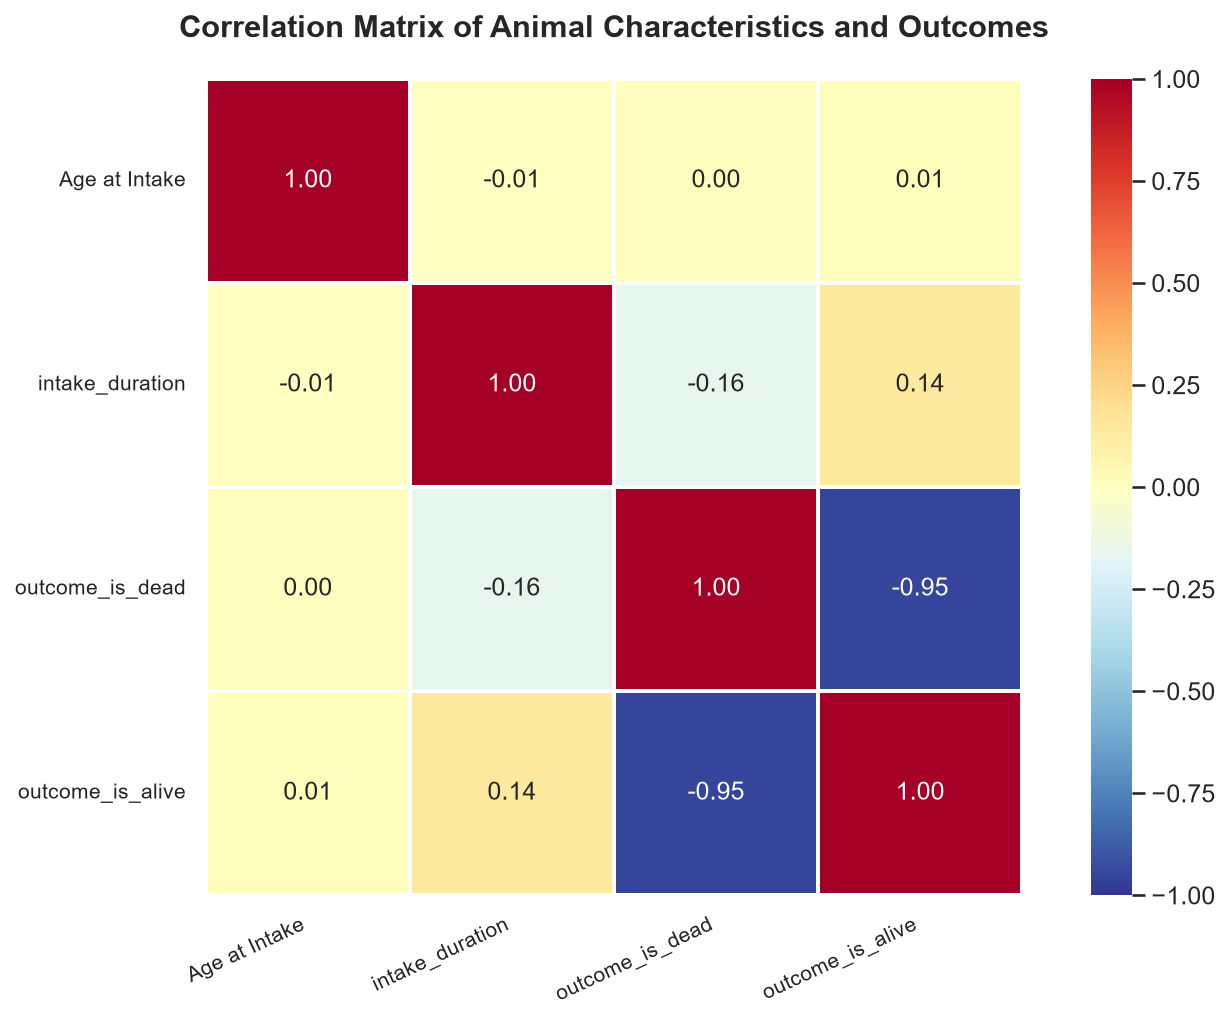

In [ ]:
corr_cols = [
    'Age at Intake',
    'intake_duration',
    'outcome_is_dead',
    'outcome_is_alive'
]

corr_data = df[corr_cols].copy()

corr_data['outcome_is_dead'] = corr_data['outcome_is_dead'].astype(int)
corr_data['outcome_is_alive'] = corr_data['outcome_is_alive'].astype(int)

correlation = corr_data.corr()

plt.figure(figsize=(10, 7), dpi=150)

sns.heatmap(
    correlation,
    annot=True,
    cmap='RdYlBu_r',
    fmt='.2f',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1,
    square=True,
    annot_kws={'size': 12}
)

plt.title(
    'Correlation Matrix of Animal Characteristics and Outcomes',
    fontsize=15,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=25, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

plt.savefig(
    'correlation_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 4.4.2 Age distribution histogram

Histogram shows the distribution of animals between the age categories

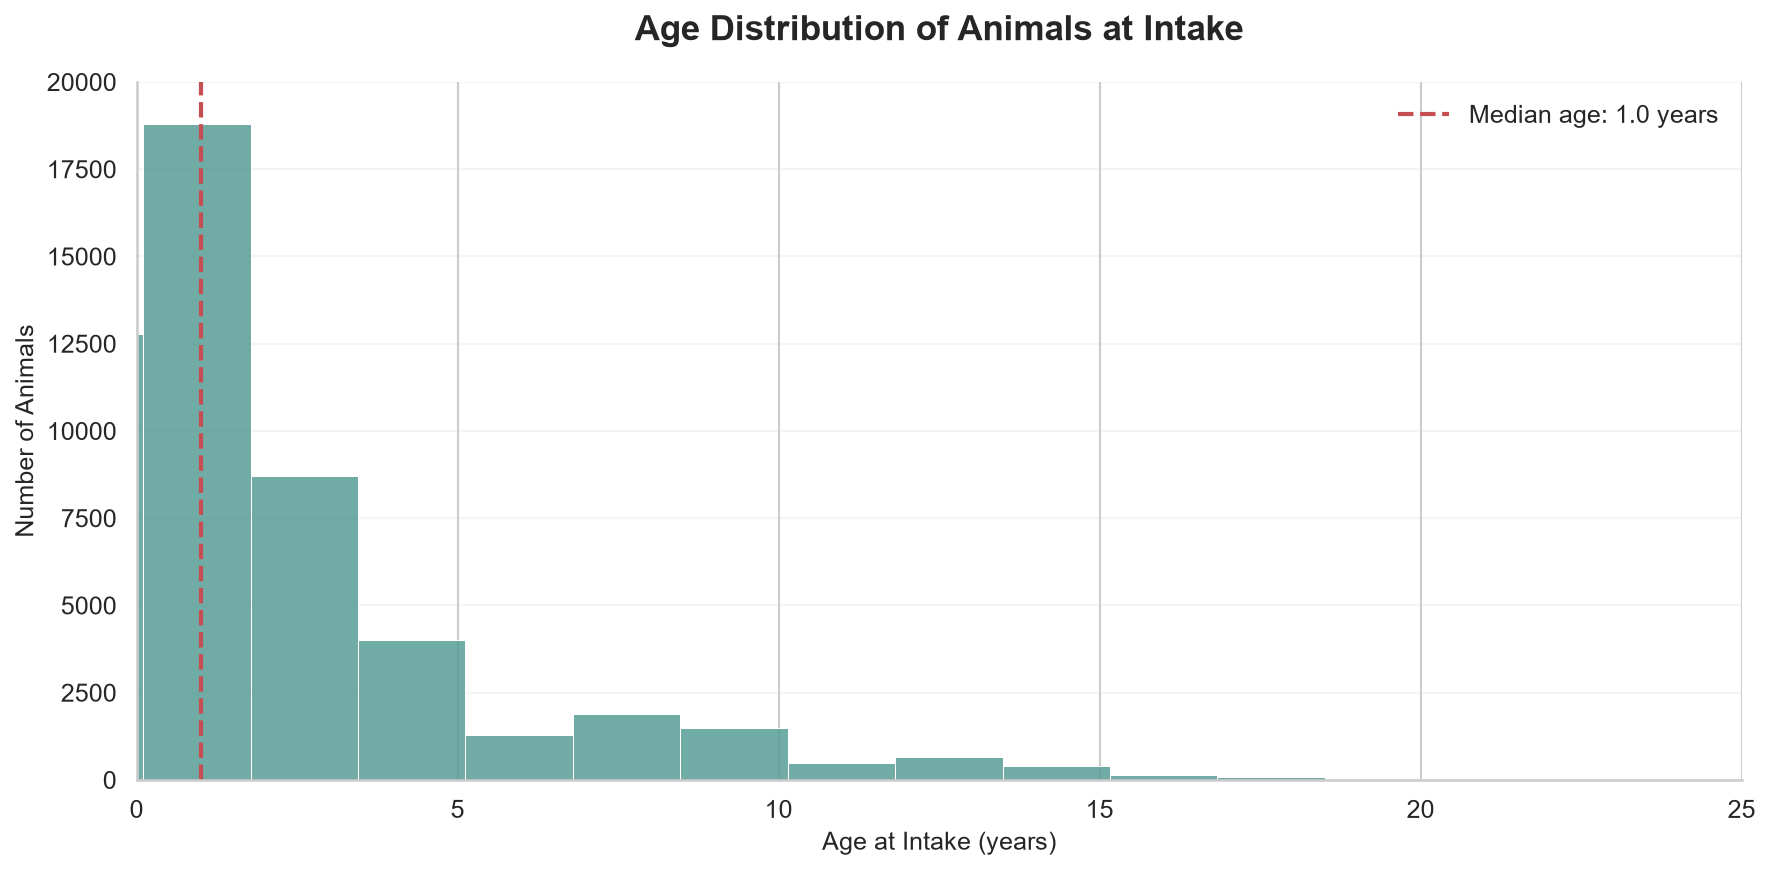

In [ ]:
plt.figure(figsize=(12, 6), dpi=150)

sns.histplot(
    data=df,
    x='Age at Intake',
    bins=40,
    kde=False,
    color='#579C95',
    edgecolor='white',
    linewidth=0.5,
    alpha=0.85
)

median_age = df['Age at Intake'].median()

plt.axvline(
    median_age,
    color='#C44E52',
    linestyle='--',
    linewidth=2,
    label=f'Median age: {median_age:.1f} years'
)

plt.title(
    'Age Distribution of Animals at Intake',
    fontsize=17,
    fontweight='bold',
    pad=20
)

plt.xlabel('Age at Intake (years)', fontsize=12)
plt.ylabel('Number of Animals', fontsize=12)
plt.ylim(0, 20000)

plt.xlim(0, 25)
plt.legend(frameon=False)

sns.despine()
plt.grid(axis='y', alpha=0.2)
plt.tight_layout()

plt.show()

### 4.4.3 Shelter composition bar graph

The bar graph shows the shelter composition by animal type

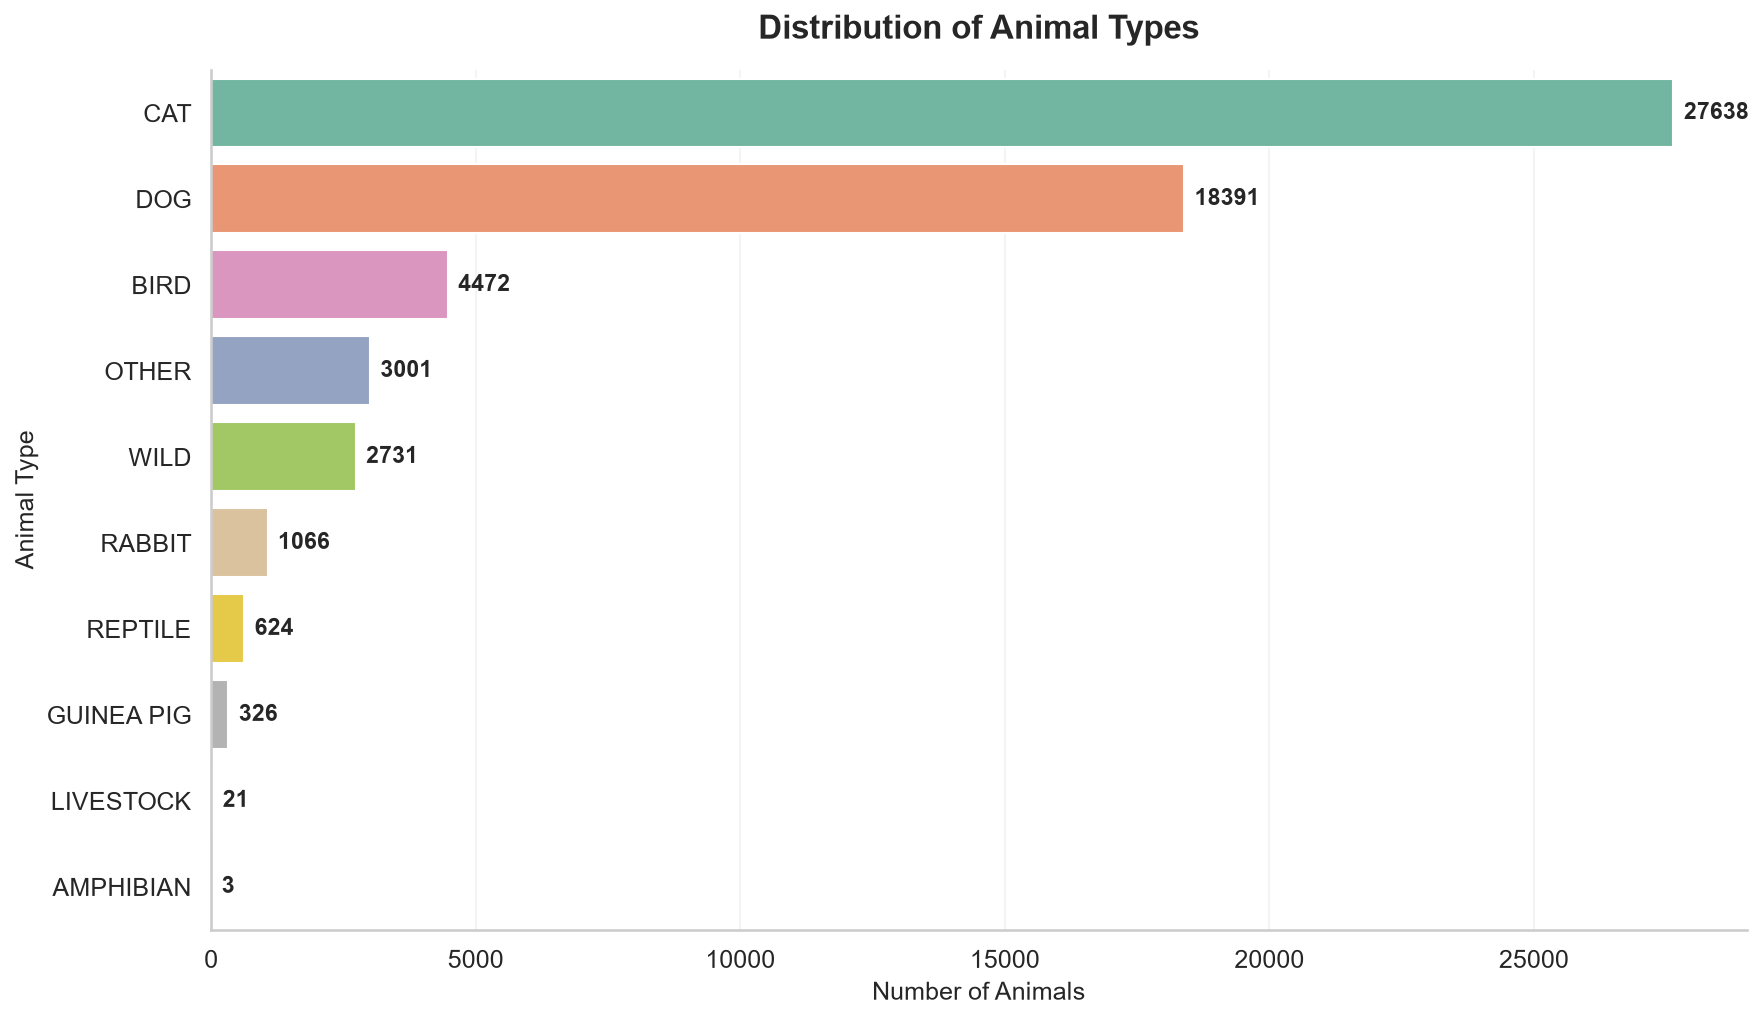

In [ ]:
plt.figure(figsize=(12, 7), dpi=150)

ax = sns.countplot(
    data=df,
    y='Animal Type',
    order=df['Animal Type'].value_counts().index,
    hue='Animal Type',
    legend=False,
    palette='Set2'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=5,
        fontsize=11,
        fontweight='bold'
    )

plt.title(
    'Distribution of Animal Types',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Number of Animals', fontsize=12)
plt.ylabel('Animal Type', fontsize=12)

sns.despine()
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()

plt.show()

### 4.4.4 Stacked bar chart on outcome distribution across animal types

Stacked bar chart shows what outcomes upon the end of the shelter stay are the most frequent across animal types

In [ ]:
# Exploring the outcome types before the chart plotting

df['Outcome Type'].value_counts(dropna=False)

Outcome Type
RESCUE                     13887
ADOPTION                   12811
EUTHANASIA                 11162
TRANSFER                    7877
RETURN TO OWNER             5841
DIED                        1450
SHELTER, NEUTER, RETURN     1395
COMMUNITY CAT               1154
TRANSPORT                    818
RETURN TO WILD HABITAT       549
FOSTER TO ADOPT              342
NaN                          299
DISPOSAL                     160
HOMEFIRST                    143
MISSING                      127
TRAP, NEUTER, RELEASE         99
DUPLICATE                     71
RETURN TO RESCUE              71
FOSTER                        17
Name: count, dtype: int64

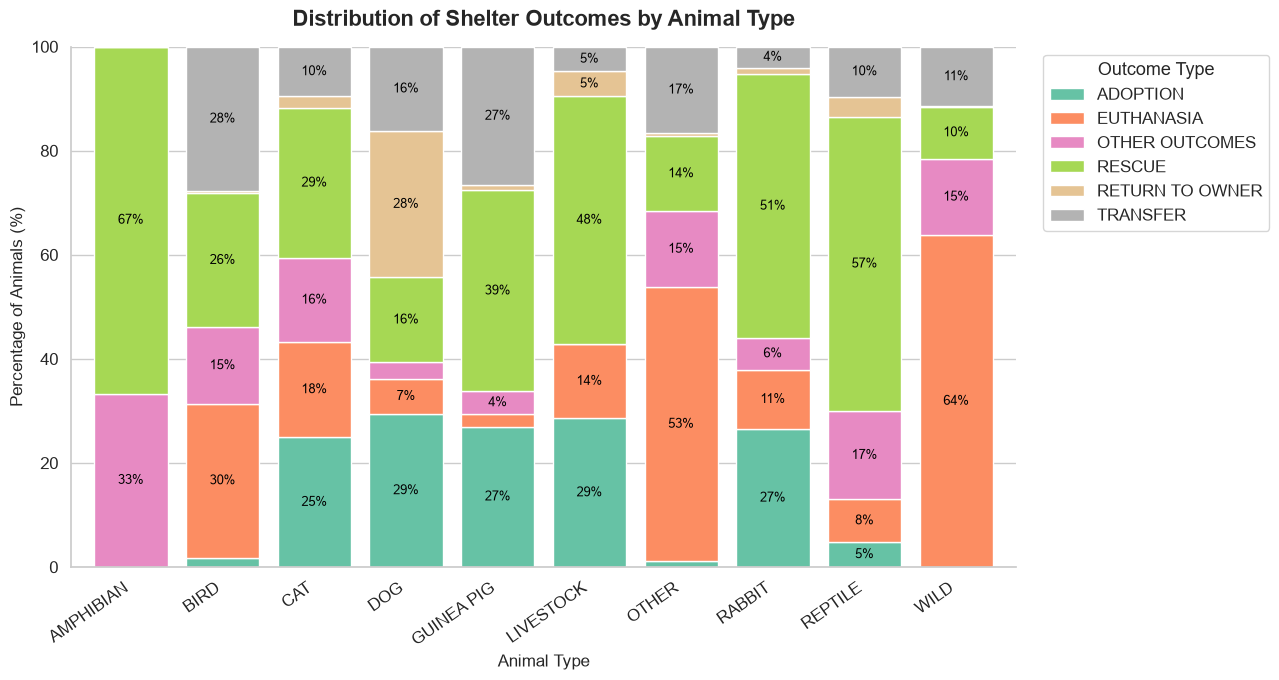

In [ ]:
top_outcomes = df['Outcome Type'].value_counts().head(5).index

df['Outcome Group'] = df['Outcome Type'].apply(
    lambda x: x if x in top_outcomes else 'OTHER OUTCOMES'
)

outcome_by_type = pd.crosstab(
    df['Animal Type'],
    df['Outcome Group'],
    normalize='index'
) * 100

ax = outcome_by_type.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    colormap='Set2',
    width=0.8
)

for container in ax.containers:
    labels = [
        f'{bar.get_height():.0f}%'
        if bar.get_height() >= 4 else ''
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9,
        fontweight='normal',
        color='black'
    )

ax.set_title(
    'Distribution of Shelter Outcomes by Animal Type',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Animal Type', fontsize=12)
ax.set_ylabel('Percentage of Animals (%)', fontsize=12)

ax.set_ylim(0, 100)

ax.legend(
    title='Outcome Type',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

sns.despine()
plt.xticks(rotation=35, ha='right')
plt.tight_layout()

plt.show()

# 5. Data Preparation

In this stage data is cleaned and prepared for training to predict an animal's shelter outcome using its characteristics and information available at intake.

## 5.1. Feature and target selection

Target variable (y): 'Outcome Type'
Predictor variables (x): animal characteristics and intake information

*outcome related information and animal identifiers are excluded to prevent target leakage

In [14]:
df['Outcome Type'].value_counts(dropna=False)

Outcome Type
RESCUE                     13887
ADOPTION                   12811
EUTHANASIA                 11162
TRANSFER                    7877
RETURN TO OWNER             5841
DIED                        1450
SHELTER, NEUTER, RETURN     1395
COMMUNITY CAT               1154
TRANSPORT                    818
RETURN TO WILD HABITAT       549
FOSTER TO ADOPT              342
NaN                          299
DISPOSAL                     160
HOMEFIRST                    143
MISSING                      127
TRAP, NEUTER, RELEASE         99
DUPLICATE                     71
RETURN TO RESCUE              71
FOSTER                        17
Name: count, dtype: int64

In [20]:
# Creating a separate dataset for data preparation and modelling

model_df = df.dropna(subset=['Outcome Type']).copy()

In [21]:
# Grouping the major categories

major_outcomes = [
    'RESCUE',
    'ADOPTION',
    'EUTHANASIA',
    'TRANSFER',
    'RETURN TO OWNER',
    'DIED'
]

# Grouping less frequent outcomes into 'OTHER' category

model_df['Outcome Target'] = model_df['Outcome Type'].where(
    model_df['Outcome Type'].isin(major_outcomes),
    'OTHER'
)

# Only these 7 categories will be predicted in the model

model_df['Outcome Target'].value_counts()

Outcome Target
RESCUE             13887
ADOPTION           12811
EUTHANASIA         11162
TRANSFER            7877
RETURN TO OWNER     5841
OTHER               4946
DIED                1450
Name: count, dtype: int64

In [47]:
# Creating a new column for the month of intake

model_df['Intake Month'] = model_df['Intake Date'].dt.month

In [52]:
# Defining predictor variables (x)

feature_columns = [
    'Animal Type',
    'Sex',
    'Primary Color',
    'Intake Condition',
    'Intake Type',
    'Intake Subtype',
    'Age at Intake',
    'Intake Month'
]

X = model_df[feature_columns].copy()
y = model_df['Outcome Target'].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (57974, 8)
Target shape: (57974,)


## 5.2. Data cleaning and correction

model_df will be used from this stage to make all adjustements here and protect the original dataset

### 5.2.1. Handling invalid date relationships

In [23]:
# Checking invalid date relationships

# DOB after intake date

invalid_dob = model_df['DOB'] > model_df['Intake Date']

# Outcome date before intake date

invalid_outcome_date = (
    model_df['Outcome Date'] < model_df['Intake Date']
)

print("DOB after intake date:", invalid_dob.sum())
print("Outcome date before intake date:", invalid_outcome_date.sum())

DOB after intake date: 253
Outcome date before intake date: 0


In [32]:
# Inspecting records with DOB after intake date

invalid_dob_records = model_df.loc[
    invalid_dob,
    ['Animal ID', 'DOB', 'Intake Date', 'Animal Type']
]

invalid_dob_records.head(15)

,Animal ID,DOB,Intake Date,Animal Type
577,A678092,2022-10-10,2022-06-21,DOG
786,A606149,2018-04-10,2018-04-09,CAT
912,A696499,2023-04-09,2023-04-05,CAT
913,A696502,2023-04-09,2023-04-05,CAT
914,A696518,2023-04-09,2023-04-05,CAT
1602,A616650,2018-10-24,2018-10-14,CAT
1603,A616651,2018-10-24,2018-10-14,CAT
1848,A594521,2017-07-30,2017-07-15,CAT
1849,A594523,2017-07-30,2017-07-15,CAT
1850,A594524,2017-07-30,2017-07-15,CAT


In [33]:
# Inspecting whether particlular animal category is more prone to invalid DOB records

invalid_dob_records['Animal Type'].value_counts()

Animal Type
CAT           189
DOG            27
RABBIT         22
OTHER          11
GUINEA PIG      4
Name: count, dtype: int64

In [34]:
# Replacing DOB values occurring after intake date

model_df.loc[invalid_dob, 'DOB'] = pd.NaT

In [37]:
# Calculating age at intake

model_df['Age at Intake'] = (
    (model_df['Intake Date'] - model_df['DOB']).dt.days / 365.25
)

model_df['Age at Intake'].describe().round(2)

count    50146.00
mean         2.19
std          3.18
min          0.00
25%          0.11
50%          1.00
75%          3.00
max         57.00
Name: Age at Intake, dtype: float64

In [41]:
# Check if the age is calculated correctly

model_df[
    ['DOB', 'Intake Date', 'Outcome Date', 'Age at Intake']
].head(10)

,DOB,Intake Date,Outcome Date,Age at Intake
0,2017-02-06,2020-05-11,2020-05-19,3.258042
1,2015-05-20,2017-05-20,2017-06-14,2.001369
2,2018-03-23,2018-05-23,2018-05-27,0.167009
3,2016-05-23,2018-05-23,2018-05-24,1.998631
4,2022-07-10,2022-07-20,2022-08-10,0.027379
5,NaT,2022-07-20,2022-08-03,NaN
6,2024-01-21,2025-01-21,2025-01-23,1.002053
7,2017-01-21,2017-08-21,2017-08-27,0.580424
8,2026-06-19,2026-07-25,2026-08-09,0.098563
9,2012-03-30,2025-11-08,2025-11-22,13.609856


In [38]:
# Check

print(
    "DOB after intake date:",
    (model_df['DOB'] > model_df['Intake Date']).sum()
)

print(
    "Missing DOB:",
    model_df['DOB'].isna().sum()
)

print(
    "Negative ages:",
    (model_df['Age at Intake'] < 0).sum()
)

DOB after intake date: 0
Missing DOB: 7828
Negative ages: 0


### 5.2.2. Handling unusual ages

In [40]:
# Checking for unusually high ages

print("Ages above 25 years:",
      (model_df['Age at Intake'] > 25).sum())

Ages above 25 years: 3


In [28]:
# Inspecting unusually high ages

model_df[
    model_df['Age at Intake'] > 25
][['Animal Type', 'DOB', 'Intake Date', 'Age at Intake']].head(10)

,Animal Type,DOB,Intake Date,Age at Intake
35281,BIRD,1969-02-09,2026-02-08,56.996578
36724,REPTILE,1993-09-15,2023-09-15,29.998631
52897,REPTILE,1967-11-26,2017-11-26,50.001369


In [42]:
# Replacing the questionable bird age with missing

model_df.loc[
    (model_df['Animal Type'] == 'BIRD') &
    (model_df['Age at Intake'] > 25),
    'Age at Intake'
] = np.nan

In [44]:
# Check

model_df[
    model_df['Age at Intake'] > 25
][['Animal Type', 'Age at Intake']]

,Animal Type,Age at Intake
36724,REPTILE,29.998631
52897,REPTILE,50.001369


# 5.3. Train-Test Split

At this stage, data is slitted into training (80%) and test (20%) sets

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Checking the resulting shapes

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (46379, 8)
Testing features: (11595, 8)
Training target: (46379,)
Testing target: (11595,)


## 5.4. Missing values handling

At this stage, variables selected for analysis will be checked for missing values and filled

In [51]:
# Checking  missing values in selected predictors

X.isnull().sum()

Animal Type            0
Sex                    0
Primary Color          0
Intake Condition       0
Intake Type            0
Intake Subtype       841
Age at Intake       7829
Intake Month           0
dtype: int64

In [53]:
# Importing the libraries for missing values filling

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [54]:
# Defining numerical and categorical features

numeric_features = [
    'Age at Intake',
    'Intake Month'
]

categorical_features = [
    'Animal Type',
    'Sex',
    'Primary Color',
    'Intake Condition',
    'Intake Type',
    'Intake Subtype'
]

In [65]:
# Numerical missing values: replacing with median

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical missing values: replacing with 'unknown'

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    ))
])

In [66]:
imputer = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [67]:
# Fitting imputer on training data and transforming both datasets

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

In [68]:
# Check

print("Training missing values:",
      pd.isna(X_train_imputed).sum())

print("Testing missing values:",
      pd.isna(X_test_imputed).sum())

Training missing values: 0
Testing missing values: 0


## 5.5. Encoding and Scaling

In [63]:
# Importing the libraries for One-Hot Encoding and Scaling

from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [70]:
# Numerical preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [71]:
# Combining both pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [72]:
# Fitting preprocessing on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Applying the same transformations to test data

X_test_processed = preprocessor.transform(X_test)

In [73]:
# Check for datasets' shapes

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (46379, 8)
Processed training shape: (46379, 155)
Original testing shape: (11595, 8)
Processed testing shape: (11595, 155)


In [78]:
# Check for missing values

print("Training missing values:",
      np.isnan(X_train_processed.data).sum())

print("Testing missing values:",
      np.isnan(X_test_processed.data).sum())

Training missing values: 0
Testing missing values: 0


In [79]:
# Inspecting the generated feature names

feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print(feature_names)

Total processed features: 155
['num__Age at Intake' 'num__Intake Month' 'cat__Animal Type_AMPHIBIAN'
 'cat__Animal Type_BIRD' 'cat__Animal Type_CAT' 'cat__Animal Type_DOG'
 'cat__Animal Type_GUINEA PIG' 'cat__Animal Type_LIVESTOCK'
 'cat__Animal Type_OTHER' 'cat__Animal Type_RABBIT'
 'cat__Animal Type_REPTILE' 'cat__Animal Type_WILD' 'cat__Sex_Female'
 'cat__Sex_Male' 'cat__Sex_Neutered' 'cat__Sex_Spayed' 'cat__Sex_Unknown'
 'cat__Primary Color_APRICOT' 'cat__Primary Color_B-C PT'
 'cat__Primary Color_BC LYNX PT' 'cat__Primary Color_BL BRINDLE'
 'cat__Primary Color_BL LYNX PT' 'cat__Primary Color_BLACK'
 'cat__Primary Color_BLK SMOKE' 'cat__Primary Color_BLK TABBY'
 'cat__Primary Color_BLK TIGER' 'cat__Primary Color_BLONDE'
 'cat__Primary Color_BLUE' 'cat__Primary Color_BLUE BRIND'
 'cat__Primary Color_BLUE CREAM' 'cat__Primary Color_BLUE FAWN'
 'cat__Primary Color_BLUE MERLE' 'cat__Primary Color_BLUE PT'
 'cat__Primary Color_BLUE TABBY' 'cat__Primary Color_BLUE TICK'
 'cat__Primary Co